# 07 · Storytelling: ¿dónde prevenir siniestros viales en CABA el mes que viene?

**Audiencia:** equipos de planificación vial y gestión pública, y público no técnico.

**Recorrido:** problema público → datos → patrones históricos → modelos → validación → perfiles territoriales → priorización → conclusiones y límites.

Este notebook **no entrena modelos**: reutiliza los resultados ya validados de los Pasos 03 a 10 (`reports/tables/`). Las figuras se guardan en `reports/figures/07_storytelling/` y alimentan la presentación y el [informe final](../docs/final_report.md).

> **Cómo leer las cifras.** Contamos siniestros **con víctimas** registrados por la policía. Un barrio con muchos siniestros no es necesariamente más peligroso por persona o por vehículo: no hay datos de tránsito para toda la ciudad.

### Guía para el lector

**Qué es este notebook.** Es la versión comunicacional del proyecto, pensada para equipos de gestión y público no técnico. **No entrena modelos ni recalcula resultados**: lee las tablas que generaron los notebooks 00 a 06 y las convierte en seis figuras con un mensaje y un límite cada una.

**Cómo leerlo.** Cada sección tiene tres partes: **Mensaje** (qué mostrar), **Límite** (qué no se puede concluir) y la figura. La sección 7 resume conclusiones, recomendación y vacíos de información.

**Dónde verificar cada cifra.**

| Sección | Mensaje | Origen de los datos |
|---|---|---|
| 1. El problema | Los siniestros con víctimas volvieron a crecer | `data/processed/hechos_clean.csv` (ETL del Paso 04); análisis en el notebook 01, §1 |
| 2. Quiénes | Motos y peatones: 81 % de los hechos mortales | `hechos_clean.csv`, período de desarrollo; notebook 01, §3 |
| 3. Dónde | 5 barrios casi siempre en el top 10; 21 nunca | `reports/tables/01_EDA/t5_frecuencia_top10_mensual.csv`; notebook 01, §5 |
| 4. ¿Un modelo anticipa mejor? | El historial cubre el 43 %; los modelos agregan +0,3 pp | `reports/tables/06_integrated_evaluation/cobertura_topk.csv`; notebook 06, §1 |
| 5. Perfiles | Borde, central y residencial | `reports/tables/05_clustering/asignacion_barrios.csv`; notebook 05, §5 y §5b |
| 6. Contar no es medir riesgo | Con el tránsito, el 43 % de los puntos cambia de cuartil | `reports/tables/06_integrated_evaluation/exposicion_corredores_2024.csv`; notebook 06, §6 |

Las figuras se guardan en `reports/figures/07_storytelling/` y se usan en la presentación y en el [informe final](../docs/final_report.md).

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures" / "07_storytelling"; FIG.mkdir(parents=True, exist_ok=True)
TB = ROOT / "reports" / "tables"
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True, "font.size": 11,
                     "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left"})
FUENTE = "Fuente: UrbanSafe CABA, con datos de BA Data (Siniestros viales, OMSV-GCBA). Siniestros con víctimas."
def save(fig, name, nota=FUENTE):
    fig.text(0.01, -0.02, nota, fontsize=8, color=INK2, ha="left", va="top")
    fig.savefig(FIG / f"{name}.png", dpi=170, bbox_inches="tight"); plt.show()
h = pd.read_csv(ROOT / "data/processed/hechos_clean.csv", dtype={"mes": str}, low_memory=False)
barrios = gpd.read_file(ROOT / "data/raw/limites/barrios.geojson").rename(columns={"nombre": "barrio"})
reg = json.loads((TB / "03_regression/regression_metrics.json").read_text(encoding="utf-8"))
clf = json.loads((TB / "04_classification/classification_metrics.json").read_text(encoding="utf-8"))
integ = json.loads((TB / "06_integrated_evaluation/integrated_metrics.json").read_text(encoding="utf-8"))
print("hechos", len(h), "| años", sorted(h["anio"].unique()))

hechos 65818 | años [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


## 1. El problema: miles de siniestros con víctimas por año, y la cifra vuelve a crecer

**Mensaje.** Tras la caída de la pandemia, los siniestros con víctimas volvieron a crecer y en 2025 alcanzaron el máximo de la serie.

**Límite.** 2025 podría ser un dato provisorio. La caída de fines de 2019 corresponde a un cambio de registro, no a una mejora real.

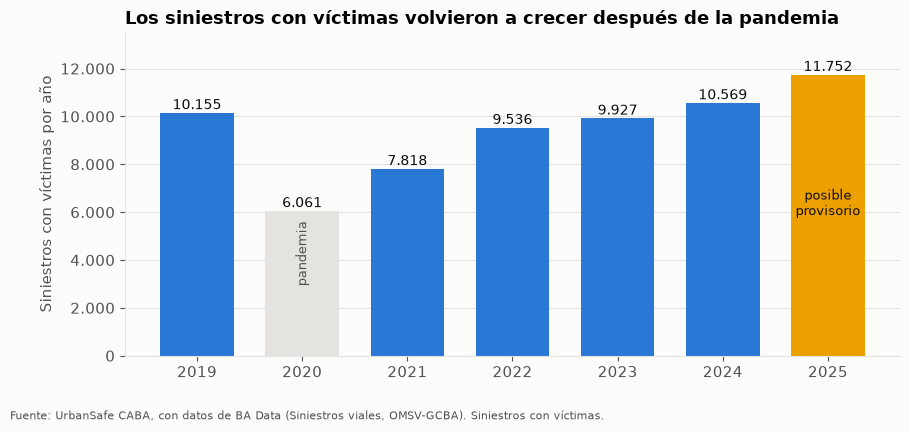

In [2]:
an = h.groupby("anio").size()
fig, ax = plt.subplots(figsize=(10, 4.2))
cols = [GRID if a == 2020 else (YELLOW if a == 2025 else BLUE) for a in an.index]
ax.bar(an.index, an.values, color=cols, width=.7); ax.grid(axis="x", visible=False)
for a, v in an.items(): ax.text(a, v + 150, f"{v:,}".replace(",", "."), ha="center", fontsize=10, color=INK)
ax.text(2020, an[2020] / 2, "pandemia", ha="center", color=INK2, fontsize=9, rotation=90)
ax.text(2025, an[2025] / 2, "posible\nprovisorio", ha="center", color=INK, fontsize=9)
ax.set_ylim(0, an.max() * 1.15); ax.set_ylabel("Siniestros con víctimas por año"); ax.set_xticks(an.index)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
ax.set_title("Los siniestros con víctimas volvieron a crecer después de la pandemia")
save(fig, "s1_evolucion_anual")

## 2. Quiénes: motociclistas y peatones concentran las muertes

**Mensaje.** Moto y peatón explican el 81 % de los siniestros mortales. El peatón es el usuario con mayor proporción de siniestros graves o mortales.

**Límite.** Sin datos de viajes por modo, no se puede afirmar qué medio es "más riesgoso por viaje".

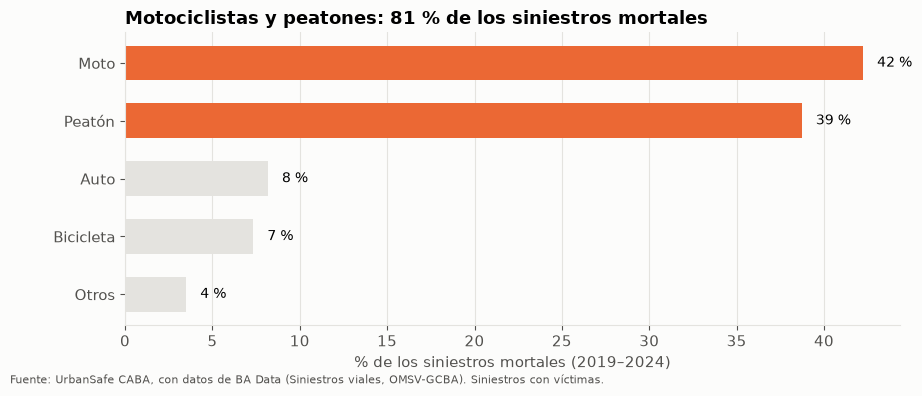

In [3]:
dev = h[h["particion"] == "desarrollo"]
mort = dev[dev["gravedad"] == "MORTAL"]["modo_victima"].replace({"TRANSPORTE PUBLICO": "OTROS", "TAXI": "OTROS", "UTILITARIO": "OTROS", "CAMION": "OTROS", "MOVIL": "OTROS", "MONOPATIN": "OTROS", "OTRO": "OTROS", "MIXTO": "OTROS"})
sh = (mort.value_counts(normalize=True) * 100).reindex(["MOTO", "PEATON", "AUTO", "BICICLETA", "OTROS"]).dropna()
fig, ax = plt.subplots(figsize=(10, 3.8))
colors = [ORANGE if m in ("MOTO", "PEATON") else GRID for m in sh.index]
ax.barh(range(len(sh)), sh.values, color=colors, height=.6); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_yticks(range(len(sh)), ["Moto", "Peatón", "Auto", "Bicicleta", "Otros"][:len(sh)])
for i, v in enumerate(sh.values): ax.text(v + .8, i, f"{v:.0f} %", va="center", fontsize=10)
ax.set_xlabel("% de los siniestros mortales (2019–2024)")
ax.set_title(f"Motociclistas y peatones: {sh[['MOTO', 'PEATON']].sum():.0f} % de los siniestros mortales")
save(fig, "s2_quienes_mortales")

## 3. Dónde: la carga se concentra y se repite en los mismos barrios

**Mensaje.** Cinco barrios están en el top 10 casi todos los meses: Balvanera, Palermo, Flores, Caballito y Recoleta. Veintiún barrios nunca entran.

**Límite.** Es **carga registrada**. Los barrios grandes acumulan más siniestros también por su tamaño: Palermo es el primero en cantidad, pero el 21.º en densidad.

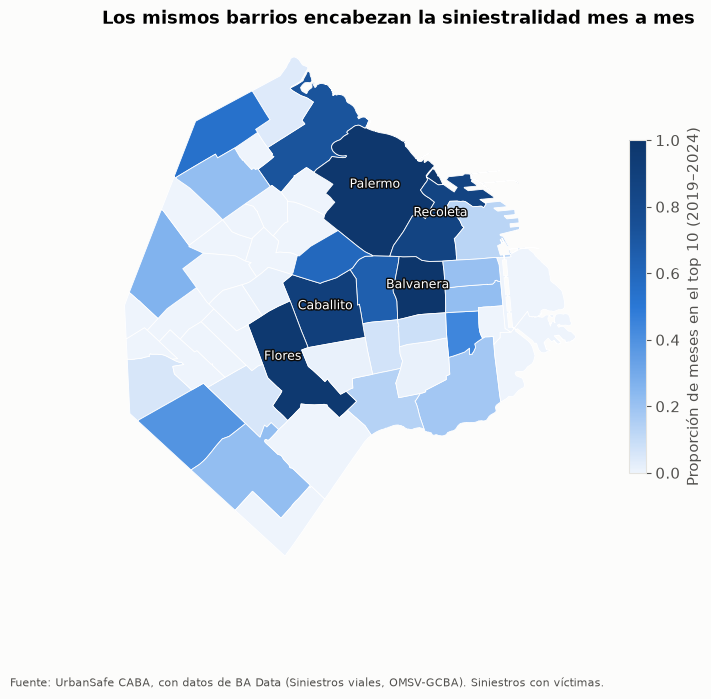

In [4]:
freq = pd.read_csv(TB / "01_EDA/t5_frecuencia_top10_mensual.csv").rename(columns={"top": "freq"})
freq.columns = ["barrio", "freq"]
g = barrios.merge(freq, on="barrio")
from matplotlib.colors import LinearSegmentedColormap
SEQ = LinearSegmentedColormap.from_list("b", ["#eef4fc", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
fig, ax = plt.subplots(figsize=(8, 7.2))
g.plot(column="freq", cmap=SEQ, vmin=0, vmax=1, ax=ax, edgecolor="white", lw=.6, legend=True, legend_kwds={"shrink": .6, "label": "Proporción de meses en el top 10 (2019–2024)"})
for _, r in g[g["freq"] > .85].iterrows():
    c = r.geometry.representative_point(); ax.annotate(r["barrio"], (c.x, c.y), ha="center", fontsize=9, color="white", path_effects=[pe.withStroke(linewidth=2, foreground=INK)])
ax.set_axis_off(); ax.set_title("Los mismos barrios encabezan la siniestralidad mes a mes")
save(fig, "s3_persistencia_mapa")

## 4. ¿Puede un modelo anticipar mejor que el historial? Casi no

**Mensaje.** Priorizar cada mes los 10 barrios con más siniestros en los últimos 12 meses ya cubre el 43 % de los siniestros del mes siguiente. Conociendo el futuro se cubriría el 45 %. Los modelos de machine learning agregan apenas +0,3 puntos.

**Límite.** El test de 2025 tiene 12 meses, así que las diferencias pequeñas no son concluyentes. La validación 2022–2024 da el mismo resultado.

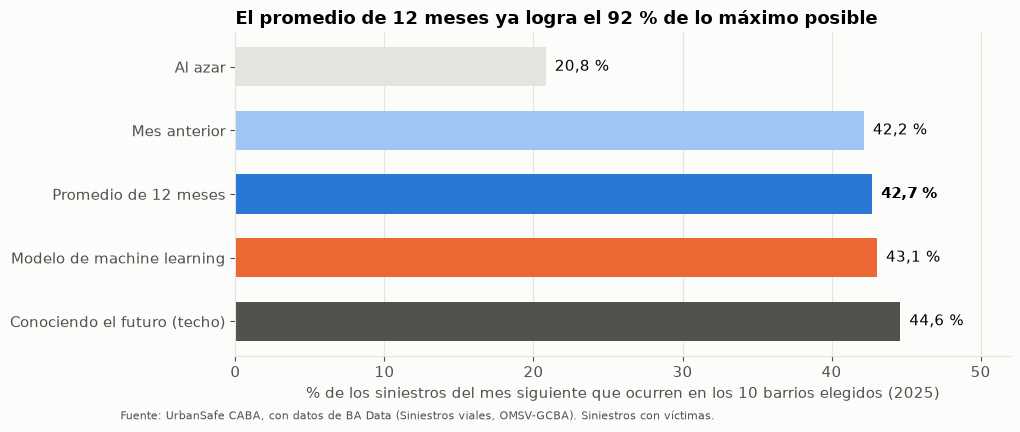

In [5]:
cov = pd.read_csv(TB / "06_integrated_evaluation/cobertura_topk.csv")
c10 = cov[(cov["K"] == 10) & (cov["conjunto"] == "TEST2025")].set_index("estrategia")["cobertura"] * 100
order = [("azar_esperado", "Al azar", GRID), ("historial_persistencia", "Mes anterior", "#9ec5f4"), ("historial_media12", "Promedio de 12 meses", BLUE),
         ("clasificador", "Modelo de machine learning", ORANGE), ("oraculo", "Conociendo el futuro (techo)", INK2)]
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, (k, lab, col) in enumerate(order):
    ax.barh(i, c10[k], color=col, height=.62); ax.text(c10[k] + .6, i, f"{c10[k]:.1f} %".replace(".", ","), va="center", fontsize=11, fontweight="bold" if k == "historial_media12" else None)
ax.set_yticks(range(len(order)), [o[1] for o in order]); ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.set_xlim(0, 52)
ax.set_xlabel("% de los siniestros del mes siguiente que ocurren en los 10 barrios elegidos (2025)")
gain = (c10["historial_media12"] - c10["azar_esperado"]) / (c10["oraculo"] - c10["azar_esperado"]) * 100
ax.set_title(f"El promedio de 12 meses ya logra el {gain:.0f} % de lo máximo posible")
save(fig, "s4_priorizacion_cobertura")

## 5. Tres perfiles de barrio para orientar el tipo de prevención

**Mensaje.** Los barrios del borde (General Paz y autopistas) tienen siniestros de vías rápidas con autos y motos. Los barrios centrales tienen más peatones y pasajeros de transporte público. Los residenciales, más motociclistas y ciclistas.

**Límite.** El perfil de borde es robusto. La diferencia entre "central" y "residencial" es más débil y debe tomarse como orientativa.

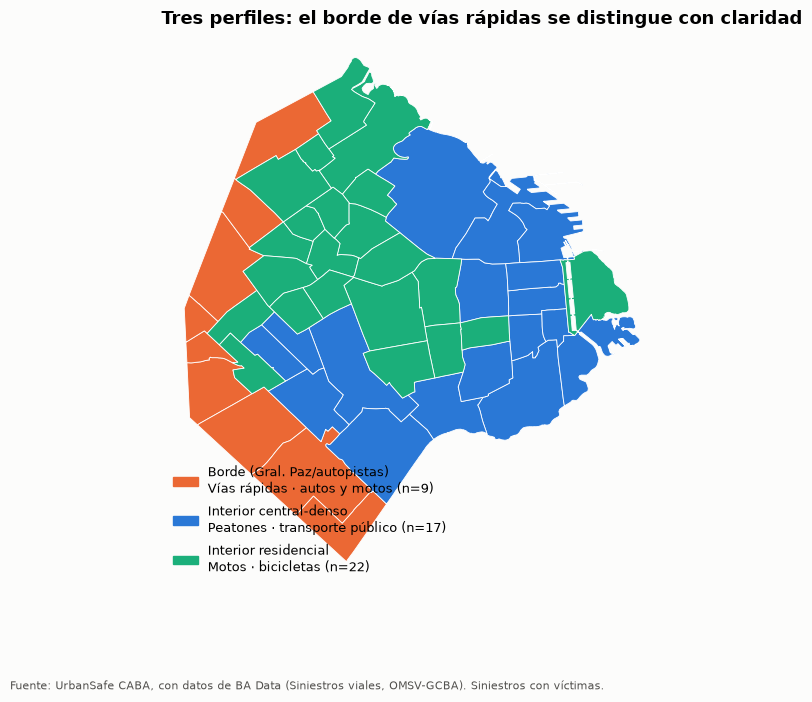

In [6]:
asg = pd.read_csv(TB / "05_clustering/asignacion_barrios.csv")
g = barrios.merge(asg[["barrio", "perfil_k3"]], on="barrio")
cols = {"Borde (Gral. Paz/autopistas)": ORANGE, "Interior central-denso": BLUE, "Interior residencial": AQUA}
desc = {"Borde (Gral. Paz/autopistas)": "Vías rápidas · autos y motos", "Interior central-denso": "Peatones · transporte público", "Interior residencial": "Motos · bicicletas"}
fig, ax = plt.subplots(figsize=(8, 7.2))
for k, c in cols.items(): g[g["perfil_k3"] == k].plot(ax=ax, color=c, edgecolor="white", lw=.6)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in cols.values()], [f"{k}\n{desc[k]} (n={int((g['perfil_k3'] == k).sum())})" for k in cols],
          frameon=False, loc="lower left", fontsize=9)
ax.set_axis_off(); ax.set_title("Tres perfiles: el borde de vías rápidas se distingue con claridad")
save(fig, "s5_perfiles")

## 6. Un aviso para la priorización: contar siniestros no es medir riesgo

**Mensaje.** En los 95 corredores con medición de tránsito, cuando se ajusta por la cantidad de vehículos, el 43 % de los puntos cambia de cuartil. Además, los barrios del borde tienen el 16 % de los siniestros pero entran poco al top 10, porque su carga se reparte entre varios barrios.

**Límite.** Las mediciones de tránsito existen solo para 2024 y en corredores. No se pueden extrapolar a toda la ciudad.

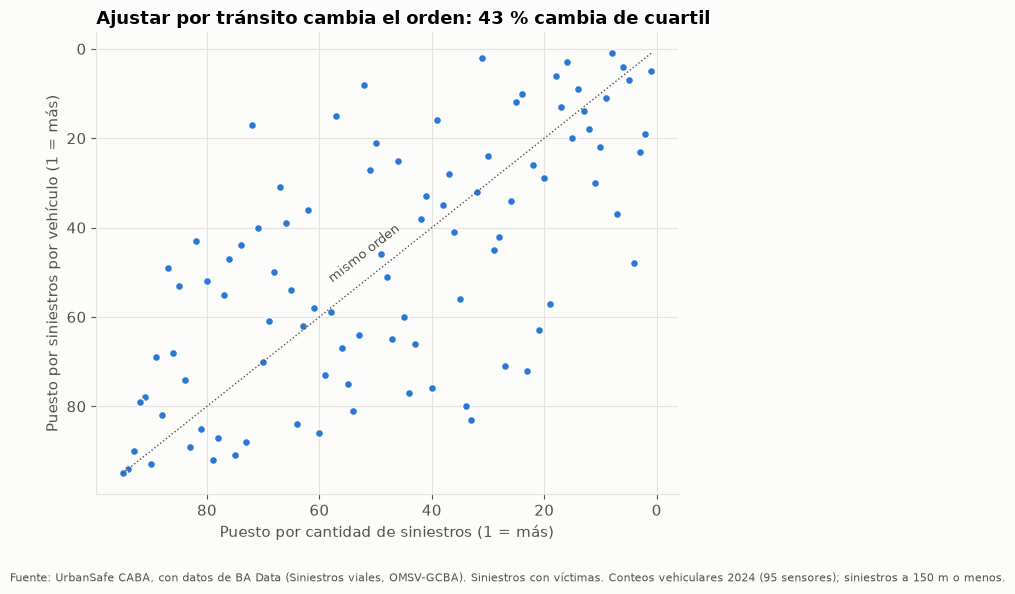

In [7]:
ex = pd.read_csv(TB / "06_integrated_evaluation/exposicion_corredores_2024.csv")
ex["rank_conteo"] = ex["hechos_150m"].rank(ascending=False, method="first"); ex["rank_tasa"] = ex["tasa_por_millon_veh"].rank(ascending=False, method="first")
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter(ex["rank_conteo"], ex["rank_tasa"], s=34, color=BLUE, edgecolor=SURFACE, lw=1.1)
ax.plot([1, len(ex)], [1, len(ex)], color=INK2, ls=":", lw=1); ax.text(len(ex) * .62, len(ex) * .55, "mismo orden", color=INK2, fontsize=9, rotation=38)
ax.set_xlabel("Puesto por cantidad de siniestros (1 = más)"); ax.set_ylabel("Puesto por siniestros por vehículo (1 = más)")
ax.invert_xaxis(); ax.invert_yaxis()
ax.set_title(f"Ajustar por tránsito cambia el orden: {integ['exposicion_h8']['pct_cambia_cuartil']:.0f} % cambia de cuartil")
save(fig, "s6_exposicion", FUENTE + " Conteos vehiculares 2024 (95 sensores); siniestros a 150 m o menos.")

## 7. Conclusiones y límites

| | |
|---|---|
| **Qué aprendimos** | La siniestralidad se concentra y se repite en los mismos barrios. Por eso, **el historial reciente es el mejor predictor** del mes siguiente: los modelos de machine learning no lo superan de forma relevante |
| **Recomendación** | Priorizar cada mes los 10 barrios con más siniestros en los últimos 12 meses (cubren alrededor del 43 %). Elegir el tipo de prevención según el perfil del barrio. En corredores con medición, revisar el orden con la tasa por vehículo |
| **Qué no se puede afirmar** | Causas ni efectos de intervenciones. Riesgo por persona o por vehículo a escala de barrio. Prioridades por gravedad (hay faltantes en los datos de siniestros graves) |
| **Qué mejoraría el análisis** | Datos de tránsito para toda la ciudad, historial fechado de la infraestructura vial y de las intervenciones, y confirmación oficial de los datos de 2025 (consulta al Observatorio) |

In [8]:
print(sorted(p.name for p in FIG.glob("*.png")))

['s1_evolucion_anual.png', 's2_quienes_mortales.png', 's3_persistencia_mapa.png', 's4_priorizacion_cobertura.png', 's5_perfiles.png', 's6_exposicion.png']
